## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this analysis is to use the Likert-scale score to measure at risk depression of clients over time to see if scores across all four counselors change or indicate a need for intervention. The program is using phD students as counselors for discounted counseling services price but it is important that the clients depression scores are watched to make sure additional intervention from the Director isn't needed to ensure the safety of the clients and the progress of the phD students in their education.

### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?

The quality characteristic being monitored is the Likert-scale score from the clients measured quantitatively and continuous from 20-100 (ordinal) but for the total summation of the score for a client it would reflect more as an interval. The higher the score the more depressed, the lower the score the less depressed. The four counselor's weekly scores are most likely correlated with one another because they are all working in the same training program, supervision, and office space but they also are also having the same timed stressors during the years through midterms and finals.

### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?

This scenario makes more sense to be treated as a Hotelling's $T^2$ chart because of the correlations between the four counselors' weekly scores of clients that I mentioned above. With the same scheduled stressful events in a semester and similar training and working conditions most likely fluctuations will all be parellel with each other for each counselor. The MSP would fit the scenario better if we were assuming that the counselor's scores behaved independently and were not correlated. If students semesters were not scheduled the same, if the technique the counselors were using was different, if the office spaces were different this would all contribute to potentially haveing independent scores as more of an assumption than in this case.

## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

In [3]:
## Q4 Code ##
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "abarre71"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}

setwd("//content//STAT-7110-Quality-Control//Assignments//HW4")

[1] "Repository already cloned to Colab."


In [5]:
# Library
install.packages(c('tidyverse','readxl','qcc'))
library(tidyverse)
library(readxl)
library(qcc)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



In [9]:
df <- excel_sheets("Counselling_PhaseI.xlsx")
glimpse(df)


 chr [1:4] "Counselor1" "Counselor2" "Counselor3" "Counselor4"


In [10]:
phase_I <- lapply(df,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseI.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(d)

})

names(phase_I) <- paste("Counselor",1:4,sep="")

phase_I["Counselor1"] |> glimpse()

List of 1
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 40 52.4 43.7 64.2 40.5 ...
  ..$ Client2: num [1:16] 46.5 51.3 43 44.7 43.9 ...
  ..$ Client3: num [1:16] 38.3 45.6 50.6 50.5 54.4 ...
  ..$ Client4: num [1:16] 57.8 29.1 49.5 45.2 32.8 ...
  ..$ Client5: num [1:16] 47.6 50 39.5 39 49.8 ...


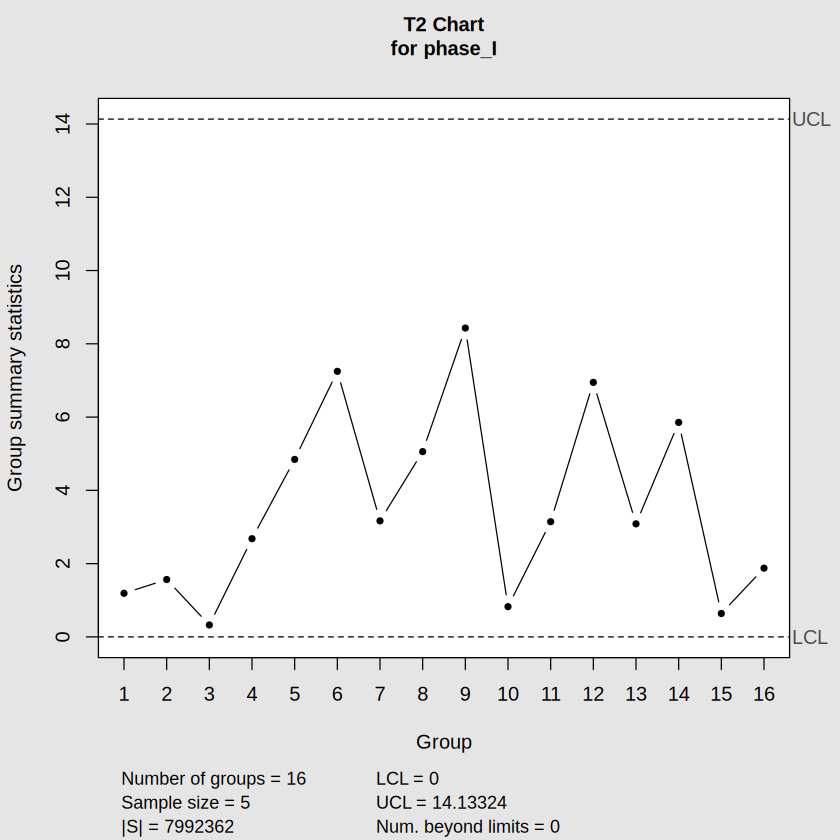

In [12]:
t2_phase_I<-mqcc(phase_I,type = 'T2')

In [14]:
t2_phase_I$violations

$beyond.limits
integer(0)

$violating.runs
numeric(0)

$beyond.pred.limits
integer(0)

Yes, we have evidence of statistical control. None of the values exceed the UCL and LCL. We can proceed with phase II.

### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [16]:
## Q5 Code ##
t2_phase_I$center
t2_phase_I$cov

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

,Counselor1,Counselor2,Counselor3,Counselor4
Counselor1,64.94685,25.20394,18.73784,28.36822
Counselor2,25.20394,63.96758,30.76070,26.36930
Counselor3,18.73784,30.76070,67.29034,14.95226
Counselor4,28.36822,26.36930,14.95226,60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

In [17]:
## Q6 Code ##
df_2 <- excel_sheets("Counselling_PhaseII.xlsx")
phase_II <- lapply(df_2,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseII.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(d)

})

names(phase_II) <- paste("Counselor",1:4,sep="")

phase_II["Counselor1"] |> glimpse()

List of 1
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 55.5 50.9 24.3 51.1 53.6 ...
  ..$ Client2: num [1:16] 57 36.5 55.5 53.9 60.2 ...
  ..$ Client3: num [1:16] 51.5 47 39.9 37.6 40.2 ...
  ..$ Client4: num [1:16] 30 42.7 41.6 46.3 41.9 ...
  ..$ Client5: num [1:16] 48.9 26.9 43.6 54.2 41.7 ...


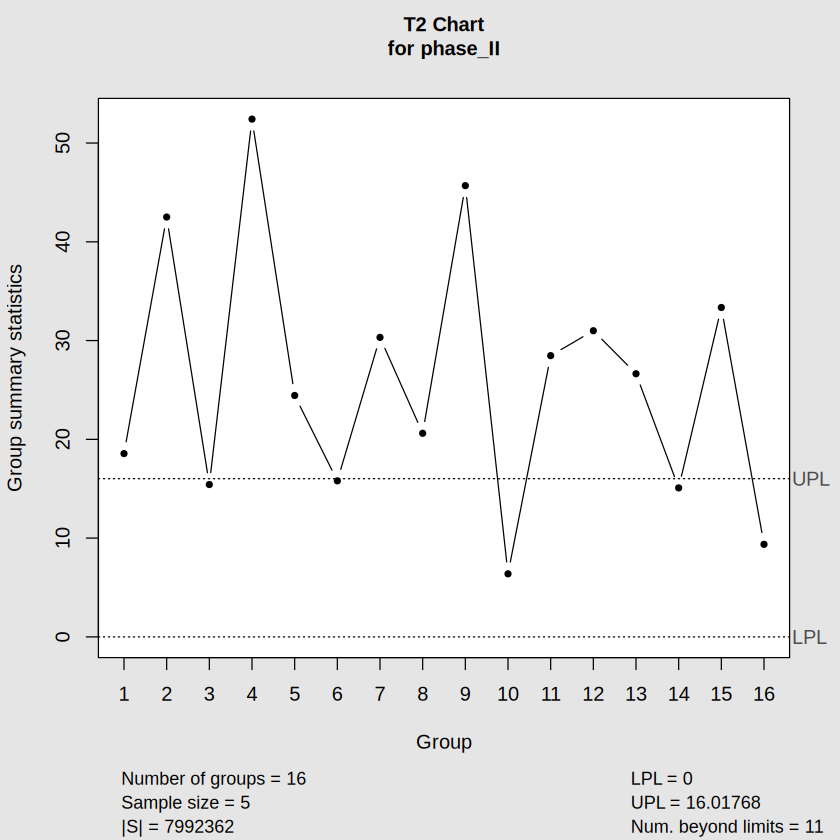

In [20]:
t2_phase_II<-mqcc(phase_II,type = 'T2',
  center = t2_phase_I$center,
  cov = t2_phase_I$cov,
  limits = F, pred.limits = T, plot = T)

There is evidence of being out of statistical control. There are 11 points beyond the UPL.

In [23]:

lapply(phase_II,FUN=function(x){

  return(mean(rowMeans(x)))

})

$Counselor1
[1] 46.16112

$Counselor2
[1] 44.43162

$Counselor3
[1] 59.6185

$Counselor4
[1] 44.552

Looks like Counselor3 may be the culprit. Now generating the individual shewhart and s charts.

In [24]:
c4 <- 0.94 #based on the Tables of Constants for Control charts

c1_xbar <- t2_phase_I$center[1]
c2_xbar <- t2_phase_I$center[2]
c3_xbar <- t2_phase_I$center[3]
c4_xbar <- t2_phase_I$center[4]

c1_sd <- sqrt(t2_phase_I$cov[1,1])/c4
c2_sd <- sqrt(t2_phase_I$cov[2,2])/c4
c3_sd <- sqrt(t2_phase_I$cov[3,3])/c4
c4_sd <- sqrt(t2_phase_I$cov[4,4])/c4

c1_ucl <- c1_xbar + 3*c1_sd
c1_lcl <- c1_xbar - 3*c1_sd

c2_ucl <- c2_xbar + 3*c2_sd
c2_lcl <- c2_xbar - 3*c2_sd

c3_ucl <- c3_xbar + 3*c3_sd
c3_lcl <- c3_xbar - 3*c3_sd

c4_ucl <- c4_xbar + 3*c4_sd
c4_lcl <- c4_xbar - 3*c4_sd

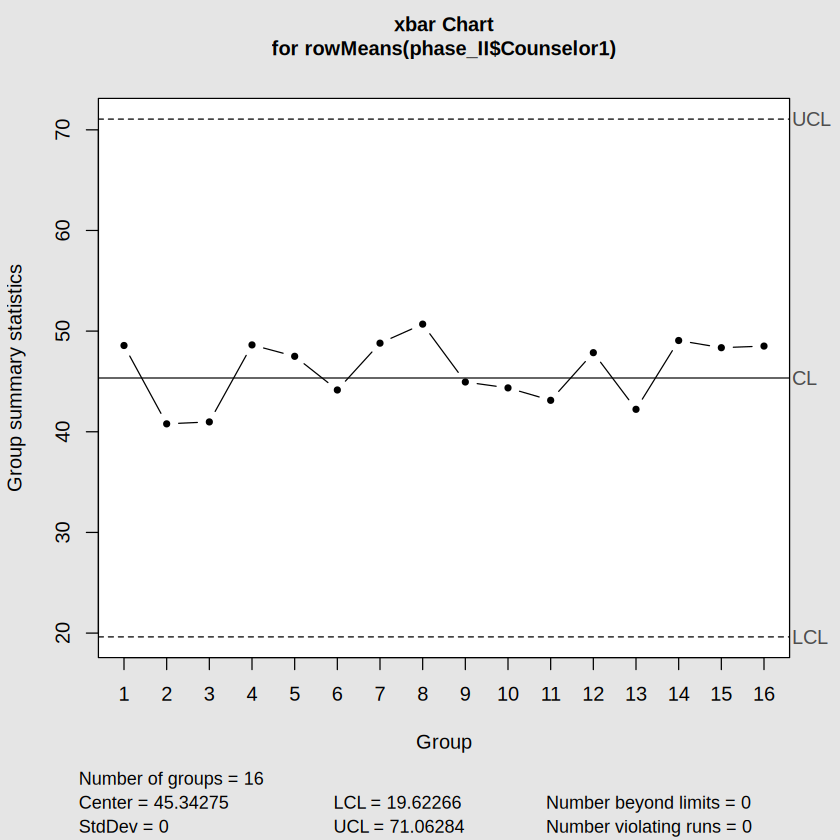

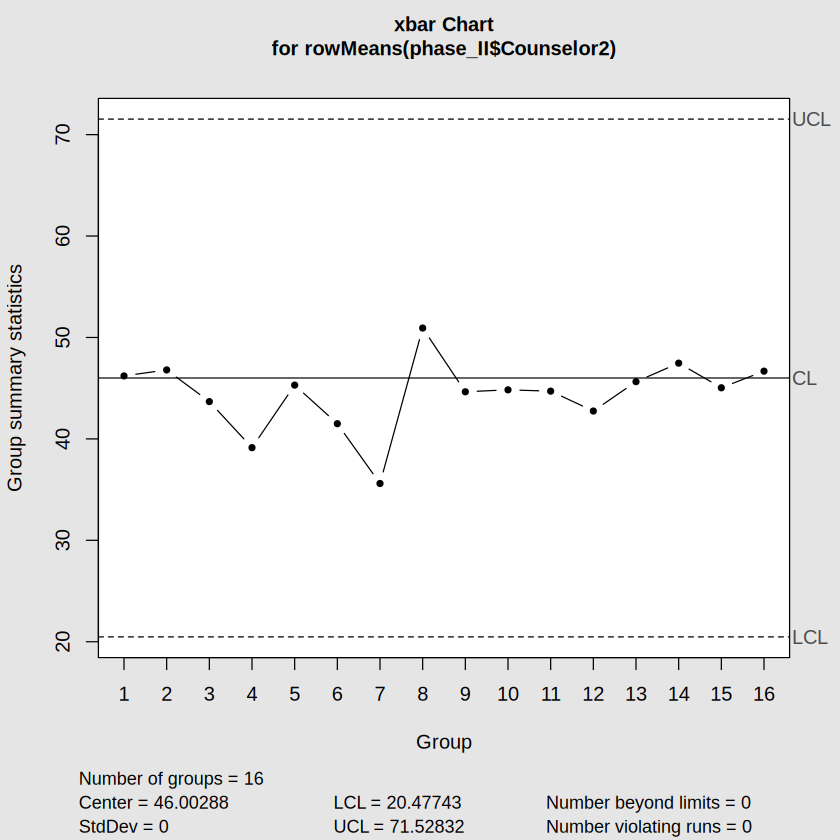

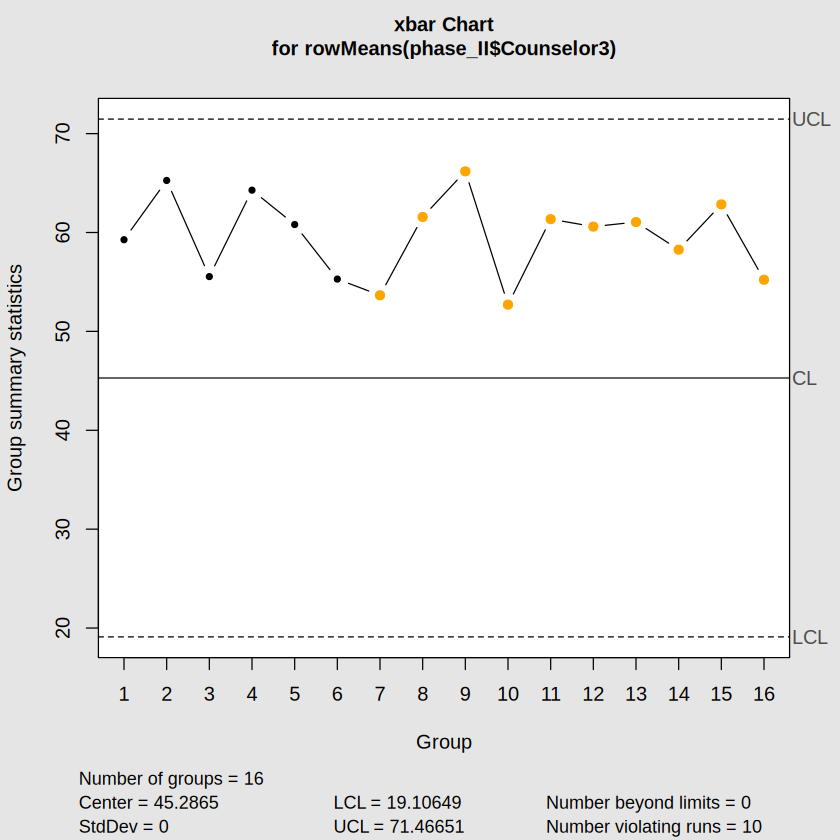

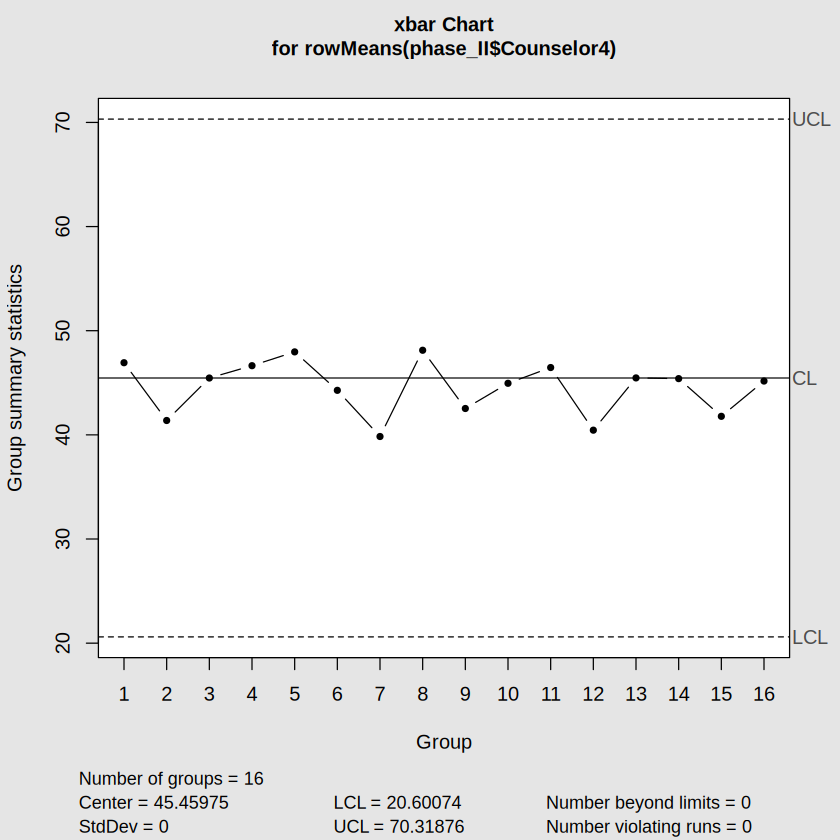

In [31]:
xbarc1 <- qcc(rowMeans(phase_II$Counselor1),
             type="xbar",
             center=c1_xbar,
             sigma=c1_sd,
             sizes=5,
             limits=c(c1_lcl,c1_ucl))

xbarc2 <- qcc(rowMeans(phase_II$Counselor2),
             type="xbar",
             center=c2_xbar,
             sigma=c2_sd,
             sizes=5,
             limits=c(c2_lcl,c2_ucl))

xbarc3 <- qcc(rowMeans(phase_II$Counselor3),
             type="xbar",
             center=c3_xbar,
             sigma=c3_sd,
             sizes=5,
             limits=c(c3_lcl,c3_ucl))

xbarc4 <- qcc(rowMeans(phase_II$Counselor4),
             type="xbar",
             center=c4_xbar,
             sigma=c4_sd,
             sizes=5,
             limits=c(c4_lcl,c4_ucl))

The xbar chart for phase II data for Counselor3 is showing that there are no points out beyond the limits but there are 10 violating runs. This is showing that the phase II data is higher than the center line consistently for Counselor3 compared to their phase I data. I will not do the s chart to see what the standard deviation of scores is showing per counselor compared to phase I.

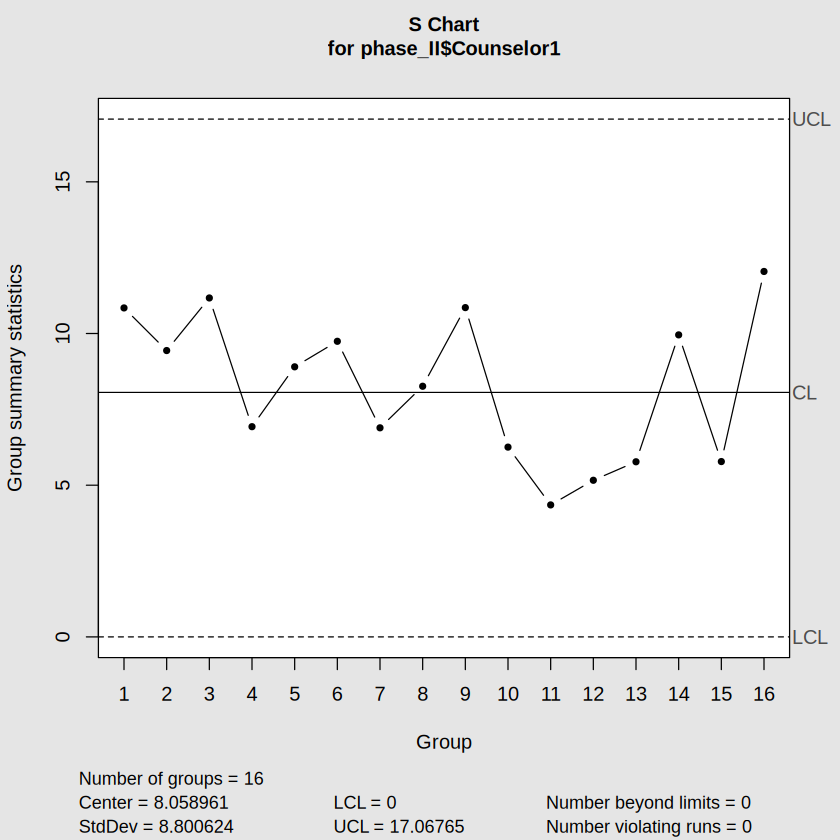

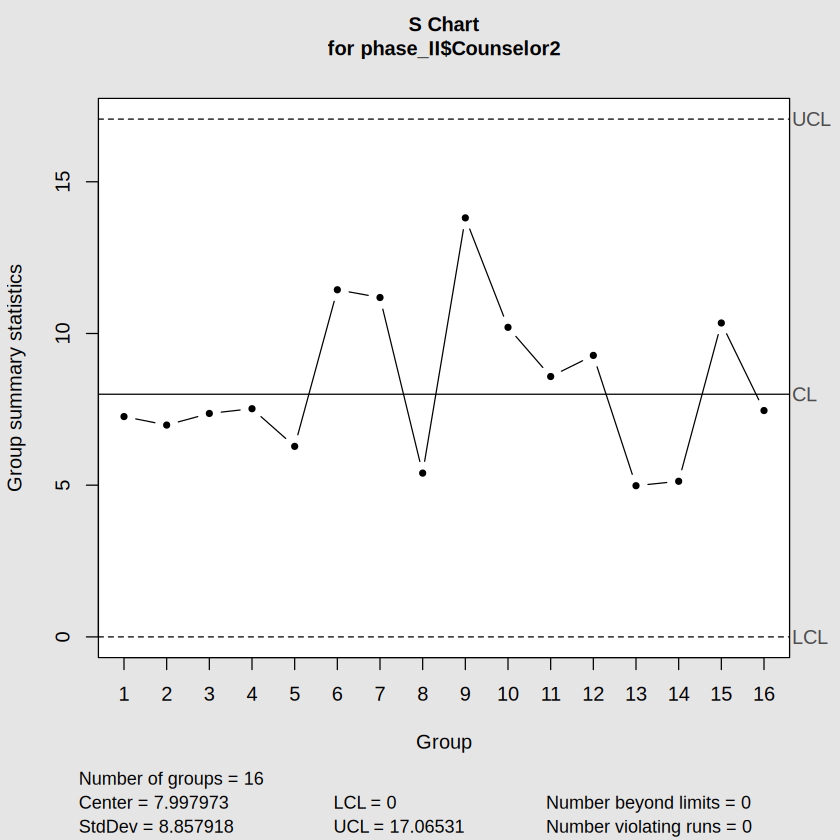

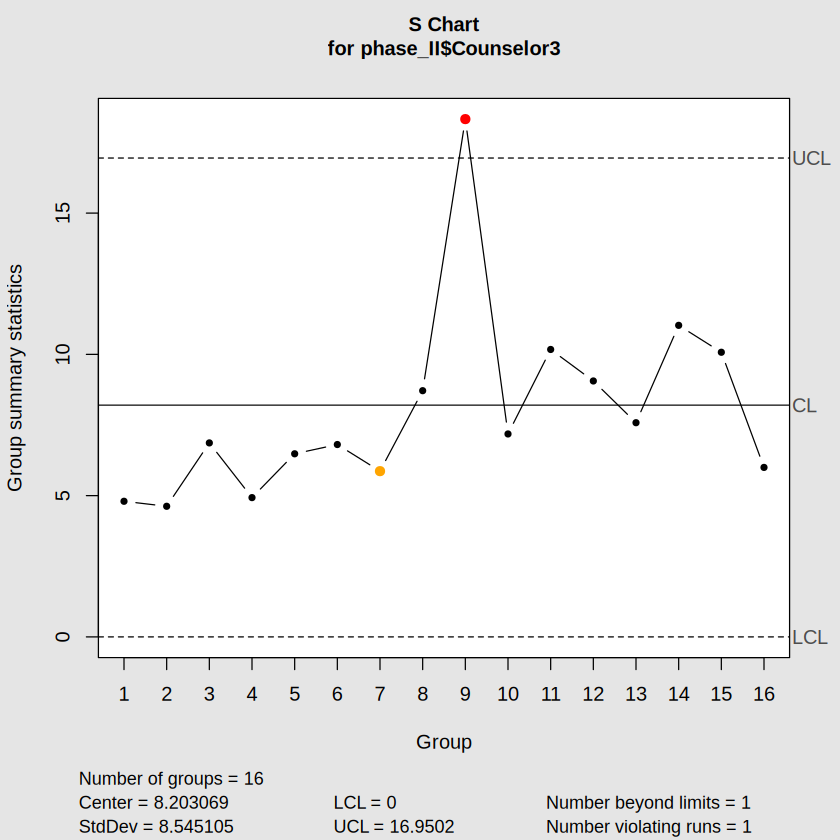

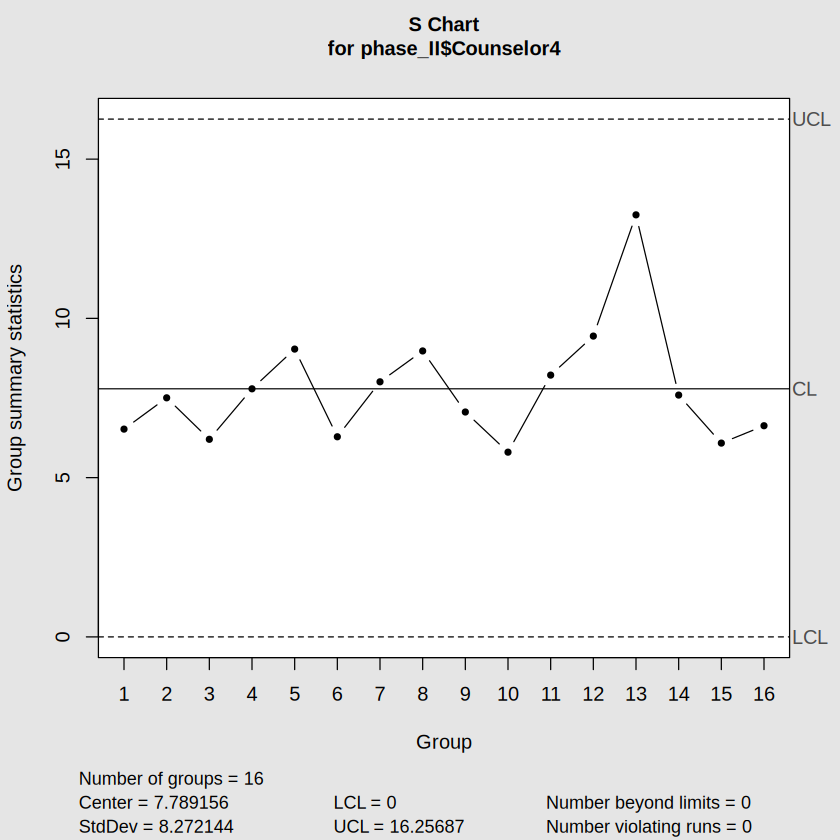

In [37]:
s_c1<-qcc(phase_II$Counselor1,
  type = 'S',
  center = c4 * c1_sd,
  sigma = c1_sd,
  sizes = 5)

s_c2<-qcc(phase_II$Counselor2,
  type = 'S',
  center = c4 * c2_sd,
  sigma = c2_sd,
  sizes = 5)

s_c3<-qcc(phase_II$Counselor3,
  type = 'S',
  center = c4 * c3_sd,
  sigma = c3_sd,
  sizes = 5)

s_c4<-qcc(phase_II$Counselor4,
  type = 'S',
  center = c4 * c4_sd,
  sigma = c4_sd,
  sizes = 5)

Counselor3 is showing statistical out of control with exceeding the limits for one point. This is showing that the standard deviation of the five client scores for this week are more variable than phase I data and these standard deviation of the depression scores is out of statistical control.

In conclusion, counselor3 is showing evidence of out of statistical control depression scores.

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

The benefit is that it can simultaneously reveal patterns that separating the charts may not because the chart is accounting for correlations between multiple variables. This can be a time saver if you are trying to anlayze multiple variables together. The other benefit is using multivariate controls can reduce false alarm rate inflation.

The limiation is interpretability and being able to directly identify variables that are out of control. The additional univariate charts are needed.

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

In [40]:

lapply(phase_I,FUN=function(x){

  return(mean(rowMeans(x)))

})


lapply(phase_II,FUN=function(x){

  return(mean(rowMeans(x)))

})

$Counselor1
[1] 45.34275

$Counselor2
[1] 46.00288

$Counselor3
[1] 45.2865

$Counselor4
[1] 45.45975

$Counselor1
[1] 46.16112

$Counselor2
[1] 44.43162

$Counselor3
[1] 59.6185

$Counselor4
[1] 44.552

I would further investigate the initial 'before counseling' scores of the clients for each counselor as well to make sure that some of what we are seeing isn't that counselor3 has had significantly more depressed clients to start with in a semester. I would consider another chart such as EWMA so we could detect gradual change over time to assess if depression is improving with an emphasis on recent observations.

I would also look at how the school schedule has lined up with these scores to see if the technically OOC point we see for counselor3 is lined up with midterms week.

I would look to add some additional training for counselor3 and continue to monitor client responses to make sure that the numbers are not continueing to increase depression scores or not change them and look to seek other solutions for those clients.

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

Yes, you could assume they are independent of one another as well but it could inflate the false rate alarm so using the adjusted L rate will help account for this.

In [45]:
glimpse(phase_I)

List of 4
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 40 52.4 43.7 64.2 40.5 ...
  ..$ Client2: num [1:16] 46.5 51.3 43 44.7 43.9 ...
  ..$ Client3: num [1:16] 38.3 45.6 50.6 50.5 54.4 ...
  ..$ Client4: num [1:16] 57.8 29.1 49.5 45.2 32.8 ...
  ..$ Client5: num [1:16] 47.6 50 39.5 39 49.8 ...
 $ Counselor2: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 37.2 46.8 39.2 52.2 46.2 ...
  ..$ Client2: num [1:16] 49.2 45.7 47.2 31.1 52.8 ...
  ..$ Client3: num [1:16] 48.6 34 52.5 57.8 45.5 ...
  ..$ Client4: num [1:16] 53.2 36.6 45.5 46.2 44.2 ...
  ..$ Client5: num [1:16] 43.5 49.7 50.1 59.8 48.5 ...
 $ Counselor3: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 53.3 57.2 46.3 54.6 40.2 ...
  ..$ Client2: num [1:16] 49.2 45.8 40.5 36.5 55.5 ...
  ..$ Client3: num [1:16] 39.7 45.5 50.6 53.8 55.9 ...
  ..$ Client4: num [1:16] 33.4 39 37.8 38.4 47.2 ...
  ..$ Client5: num [1:16] 53.6 37 55.5 37.7 58.7 ...
 $

In [48]:
## Q9 Code ##

c_list <- lapply(phase_I,FUN=function(x){

  df <- tibble(Means = rowMeans(x),
               Ranges =
                 apply(x,1,FUN=function(x){

                   max(x) - min(x)

                 }),
                Week = seq(1,16))

  return(df)

})

glimpse(c_list)

List of 4
 $ Counselor1: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 46 45.7 45.2 48.7 44.3 ...
  ..$ Ranges: num [1:16] 19.4 23.3 11.1 25.2 21.6 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...
 $ Counselor2: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 46.3 42.5 46.9 49.4 47.4 ...
  ..$ Ranges: num [1:16] 15.98 15.73 13.33 28.67 8.62 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...
 $ Counselor3: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 45.8 44.9 46.1 44.2 51.5 ...
  ..$ Ranges: num [1:16] 20.2 20.2 17.8 18.2 18.5 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...
 $ Counselor4: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 49 46.1 47.1 45.4 42.2 ...
  ..$ Ranges: num [1:16] 8.92 8.17 17.47 16.37 13.5 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...


In [49]:
install.packages('IQCC')
library(IQCC)

d2 <- d2(5)
d2
L <- 3.46

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘miscTools’


Loading required package: miscTools



[1] 2.325929

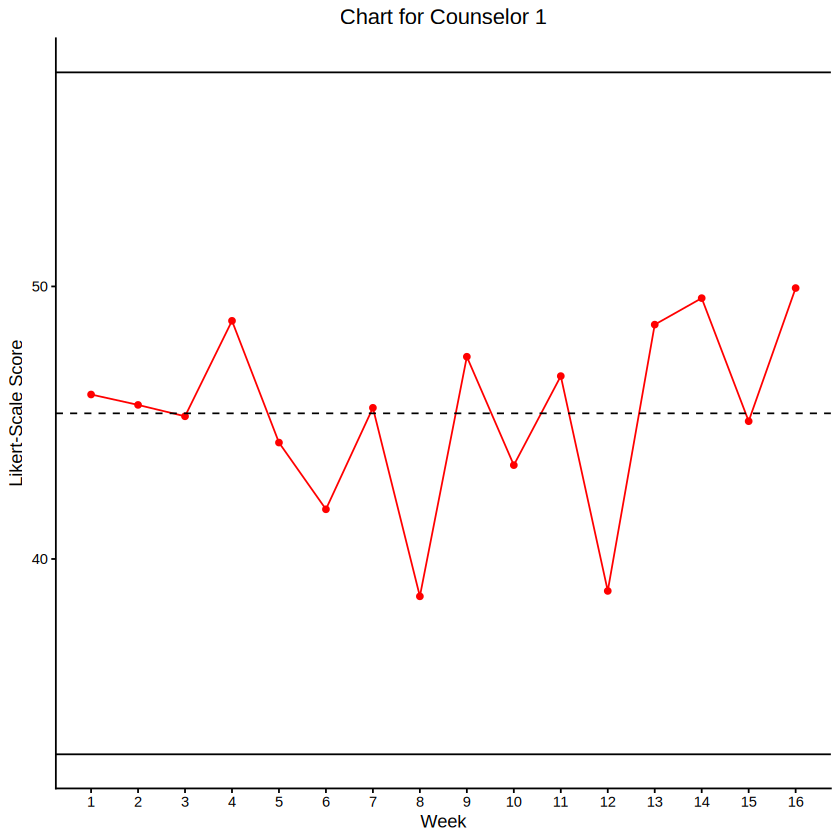

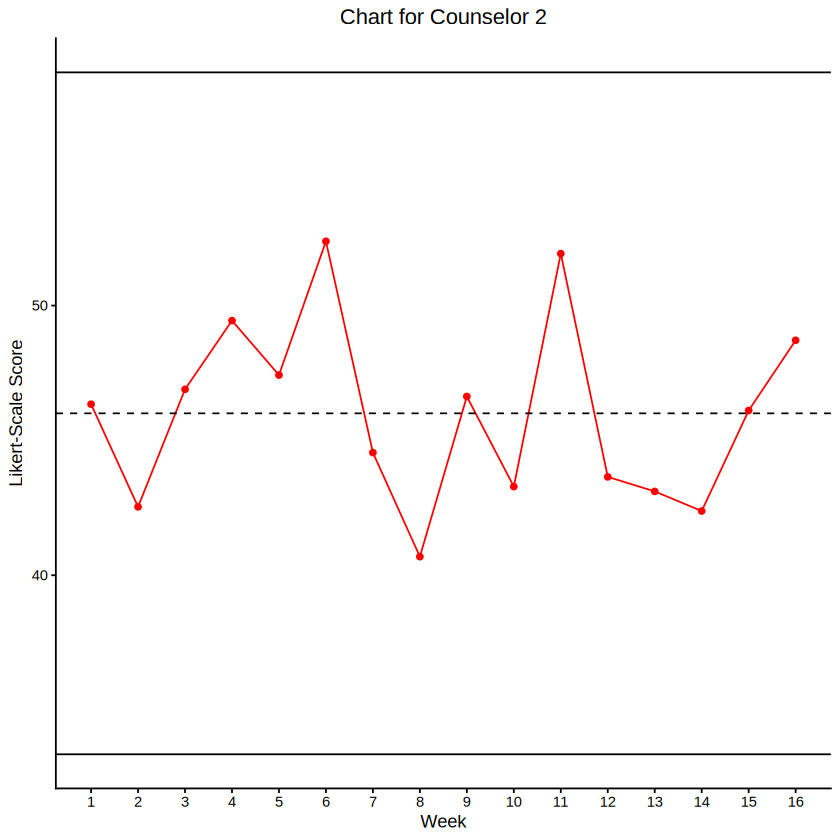

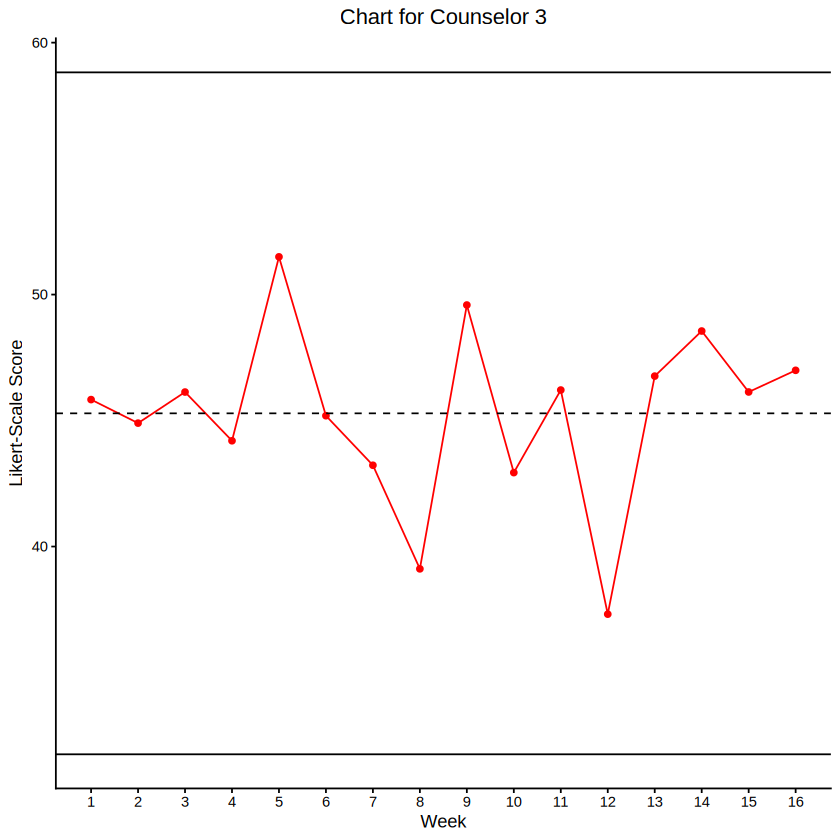

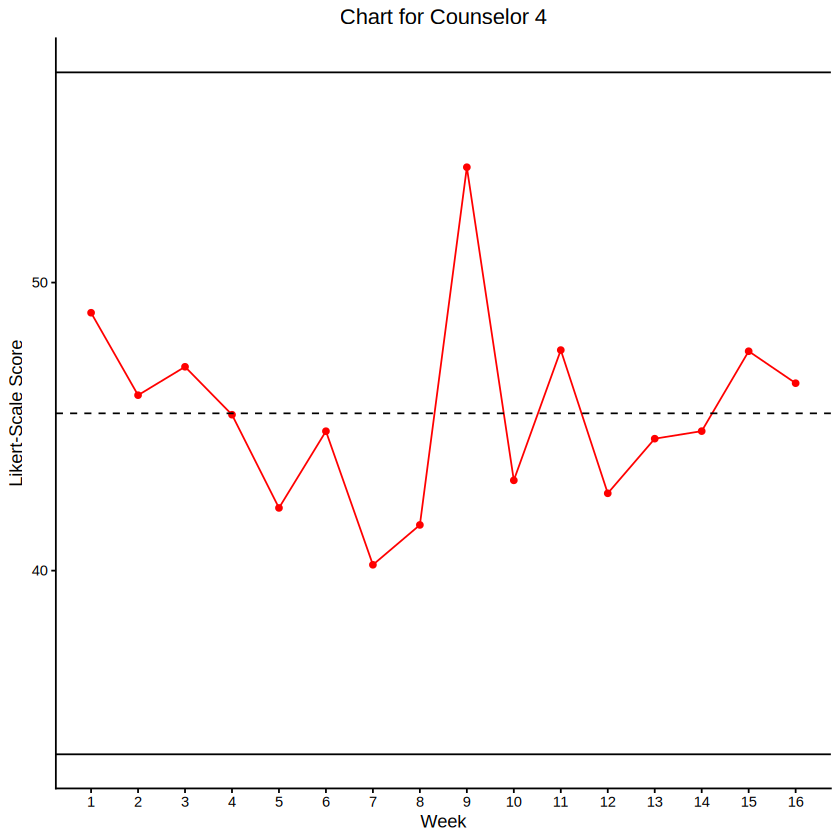

In [56]:
cfes <- lapply(seq_along(c_list), FUN = function(cid) {

  x <- c_list[[cid]]

  xdbar <- mean(x$Means)

  rbar <- mean(x$Ranges)

  UCL <- xdbar + L*rbar/(d2*sqrt(5))

  LCL <- xdbar - L*rbar/(d2*sqrt(5))

  p1_chart <- x |>
    ggplot(aes(x=Week,y=Means)) +
    geom_point(color='red') + geom_line(color='red') +
    geom_hline(yintercept=UCL,color='black') +
    geom_hline(yintercept=LCL,color='black') +
    geom_hline(yintercept=xdbar,color='black',linetype='dashed') +
    labs(x = "Week", y = "Likert-Scale Score",
         title = paste("Chart for Counselor ",cid,sep="")) +
    theme_classic() +
    theme(plot.title=element_text(hjust=0.50)) +
    scale_x_continuous(breaks = seq(1,16))

  info <- list(Center = xdbar,
               Limits = c(LCL,UCL),
               Violations = x |>
                 filter(Means > UCL | Means < LCL) |>
                 select(Week))

  print(p1_chart)

  return(info)

})

Yes, we have evidence of statistical control.

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

In [63]:
## Q10 Code ##
c_list2 <- lapply(phase_II,FUN=function(x){

  df <- tibble(Means = rowMeans(x),
               Ranges =
                 apply(x,1,FUN=function(x){

                   max(x) - min(x)

                 }),
               Week = seq(1,16))

  return(df)

})
glimpse(c_list2)

List of 4
 $ Counselor1: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 48.6 40.8 41 48.6 47.5 ...
  ..$ Ranges: num [1:16] 26.9 24 31.2 16.6 20 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...
 $ Counselor2: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 46.2 46.8 43.7 39.1 45.3 ...
  ..$ Ranges: num [1:16] 17.7 17.9 19.1 15.5 16.4 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...
 $ Counselor3: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 59.3 65.3 55.5 64.3 60.8 ...
  ..$ Ranges: num [1:16] 12.8 10.9 17.9 12.2 14.8 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...
 $ Counselor4: tibble [16 × 3] (S3: tbl_df/tbl/data.frame)
  ..$ Means : num [1:16] 46.9 41.4 45.5 46.6 48 ...
  ..$ Ranges: num [1:16] 15.5 19.2 14.2 19.1 22.1 ...
  ..$ Week  : int [1:16] 1 2 3 4 5 6 7 8 9 10 ...


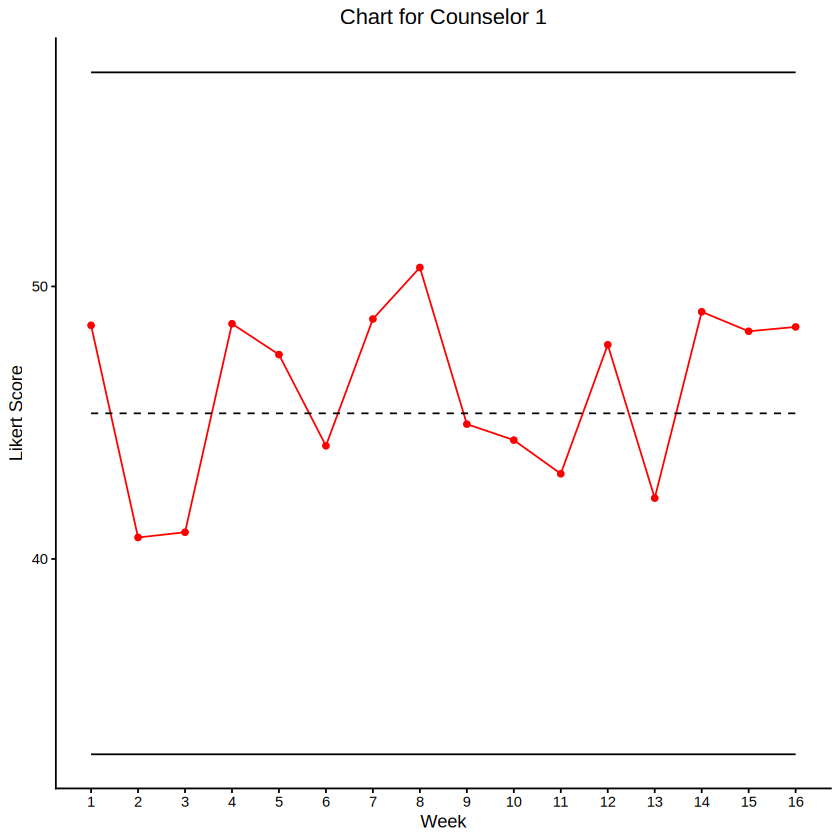

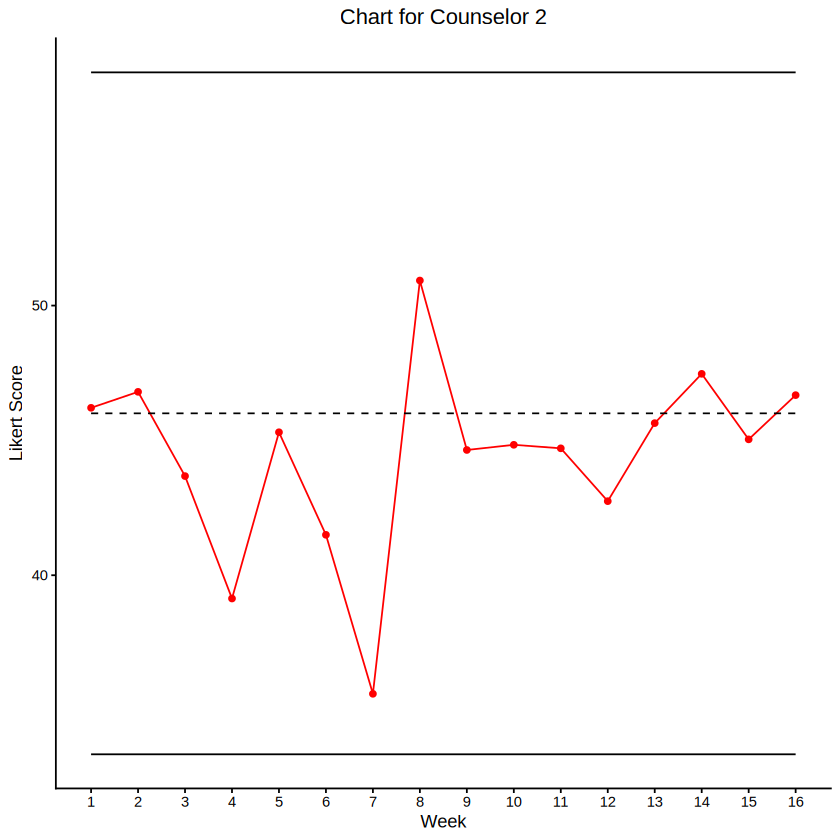

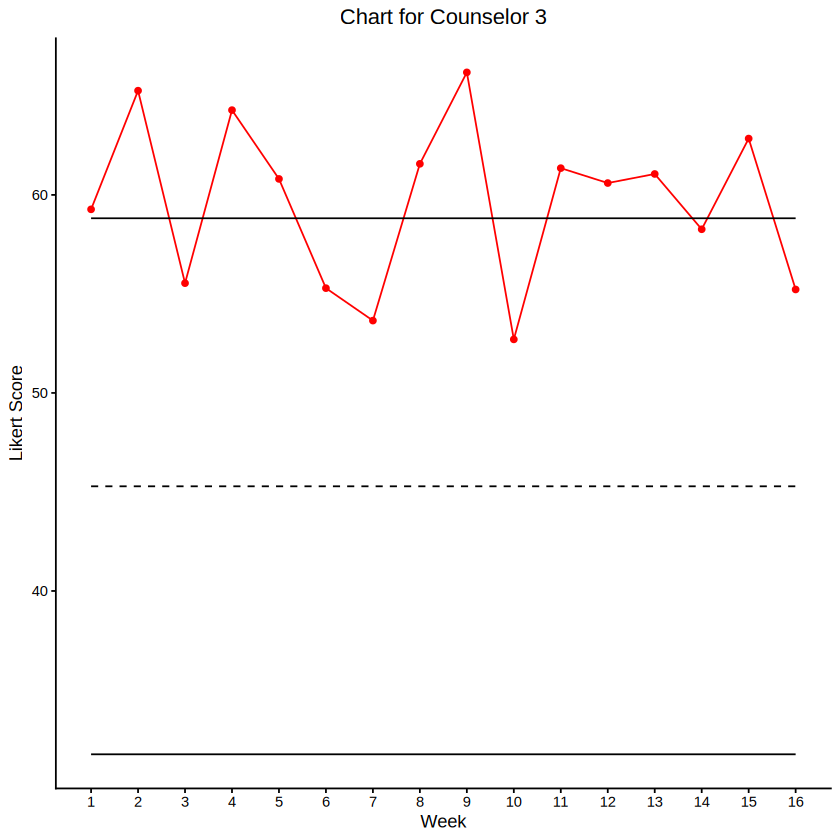

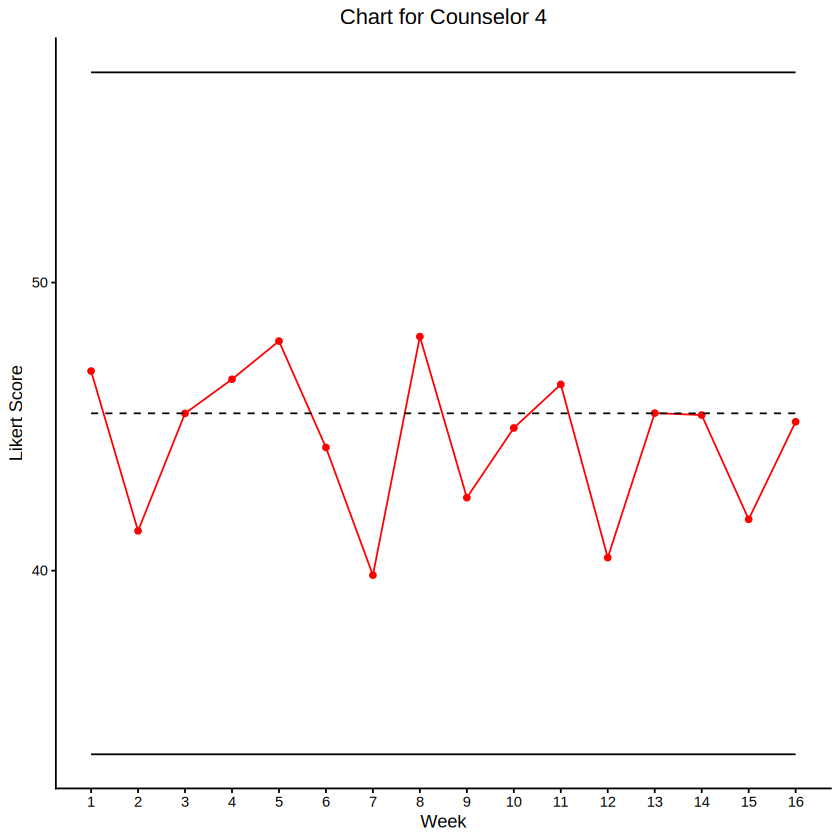

In [64]:
cfes2 <- vector('list',length=4)

for(i in 1:4){

  limits <- cfes[[i]]$Limits

  center_line <- cfes[[i]]$Center

  df <- c_list2[[i]]

  p2_chart <- df |>
    ggplot(aes(x=Week,y=Means)) +
    geom_point(color='red') + geom_line(color='red') +
    geom_line(aes(y=limits[2]),color='black') +
    geom_line(aes(y=limits[1]),color='black') +
    geom_line(aes(y=center_line),color='black',linetype='dashed') +
    labs(x = "Week", y = "Likert Score",
         title = paste("Chart for Counselor ",i,sep="")) +
    theme_classic()  +
    theme(plot.title=element_text(hjust=0.50)) +
    scale_x_continuous(breaks = seq(1,16))

  info <- list(Violations = df |>
                 filter(Means > limits[2] | Means < limits[1]) |>
                 select(Week))

  cfes2[[i]] <- info

  print(p2_chart)

}

The individual MSP plots show that counselor3 is out of statistical control, above the UCL.

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

The difference between the multivariate process and a multiple stream process is that the multivariate process monitors variables simultaneously and accounts for corelations between them where the multiple stream process has the counselors as independent processes with each counselor operating individually. This allows us to identify which counselor is OOC. From looking at the specific multivariate charts it signals that phase II data is out of control but we don't know whom. The further analysis gives us the insight that it is counselor3 so this is the downside to the additional step because the MSP charts for each variate gave us the indication for couselor3 without additional xbar and s charts.

But for this scenario the multivariate process makes more sense because all four conselors are in the same program, office space, at the same university with the same school schedule with timed areas of acedemic stress. Accounting for the correlation allows us to decrease the overall false alarm rate where as the individual multiple stream charts can inflate the overall false alarm rate if L is not adjusted correctly. The MSP chart showed 10 points of OOC for counselor3 where looking at the specific xbar and schart for counselor 3 we see that there is an indicaiton of an upward shift in scores compared to phase I and there is OOC point for standard deviation but it is not as aggregious as the 10 OOC points we see in the MSP.

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?

Based on phase I and phase II control charts I would continue to analyze and measure the Owl Nest's program. The Hotelling's $T^2$ chart showed that the overall averages of the counselors likert scores together in the phase II data was statistically OOC based on phase I but this could be due to specific counselor3 which was identified after individual xbar and s chart analysis. Counselor3's overall averaged depression scores increased from 45.29 to 59.62 based on the samples taken from five clients in the 16 week period in phase I and phase II.

When using the MSP method the results of the phase II analysis showed that counselor3 was also out of statistical control. I would look at when the increase occurred to see if the academic schedule correlated with this at all. I would also look at counselor3's clients to see if they initially started the counseling with lower scores and see about tracking progress per client of counselor3 over time. After investigating and finding a similar pattern I would recommend additional training for counselor3.  

Additionally, I would recommend implementing a better monitoring system to evaluate the effectiveness of The Owl's Nest program. Evaluating counseling effectiveness would require tracking individual clients progress from their initial assessment through each session. While the $T^2$ chart is great for identifying depression score shifts across all four counselors it doesn't account for individual progress through counseling. I would look at evaluating individual client scores over time per counselor and then track changes in those scores with EWMA and then MEWMA chart to monitor overall treands across multiple counselors.

I would continue the program but also continue to monitor the the counselor performance for the effectiveness.